   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 9.3 MB/s  0:00:00
Input and Output defined successfully!
Membership Functions created successfully!


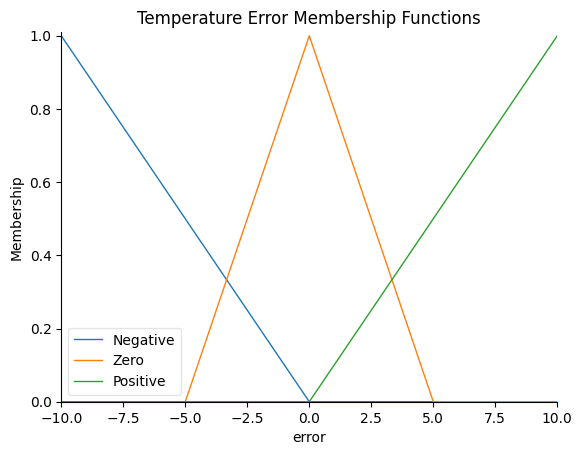

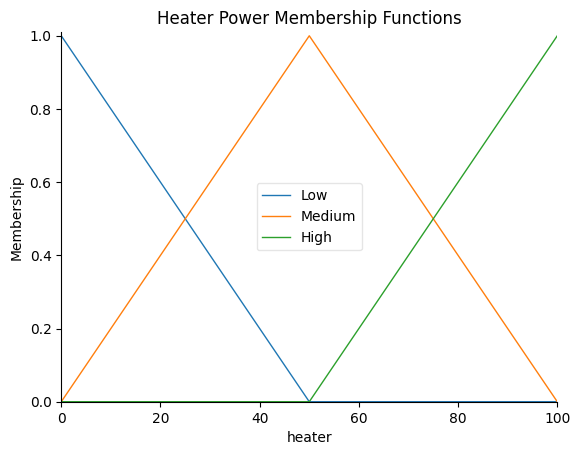

Fuzzy Rules created successfully!
Target Temperature: 23
Current Temperature: 17
Temperature Error: 6
Heater Power: 81.43 %
Simulation completed!
Final Temperature: 22.99


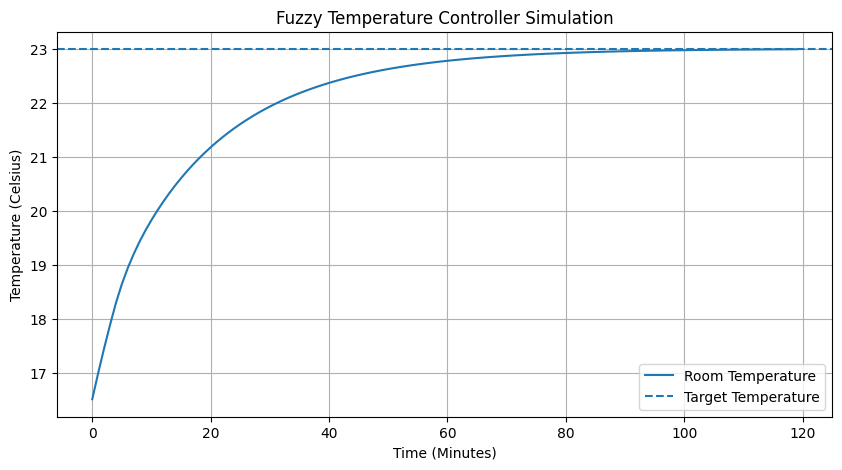

Controller function created successfully!
3 MFs - triangular completed!
3 MFs - trapezoidal completed!
5 MFs - triangular completed!
5 MFs - trapezoidal completed!
All experiments completed successfully!


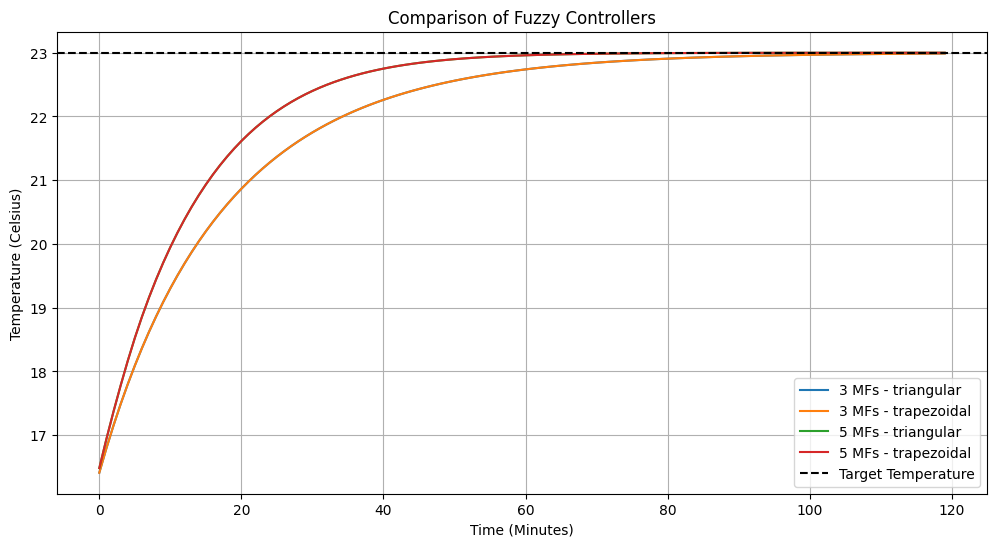

FINAL RESULTS

 3 MFs - triangular
MAE: 1.0152
Stability: 0.0127
Overshoot: 0
----------------------------------------

 3 MFs - trapezoidal
MAE: 1.0152
Stability: 0.0127
Overshoot: 0
----------------------------------------

 5 MFs - triangular
MAE: 0.7204
Stability: 0.0007
Overshoot: 0
----------------------------------------

 5 MFs - trapezoidal
MAE: 0.7204
Stability: 0.0007
Overshoot: 0
----------------------------------------


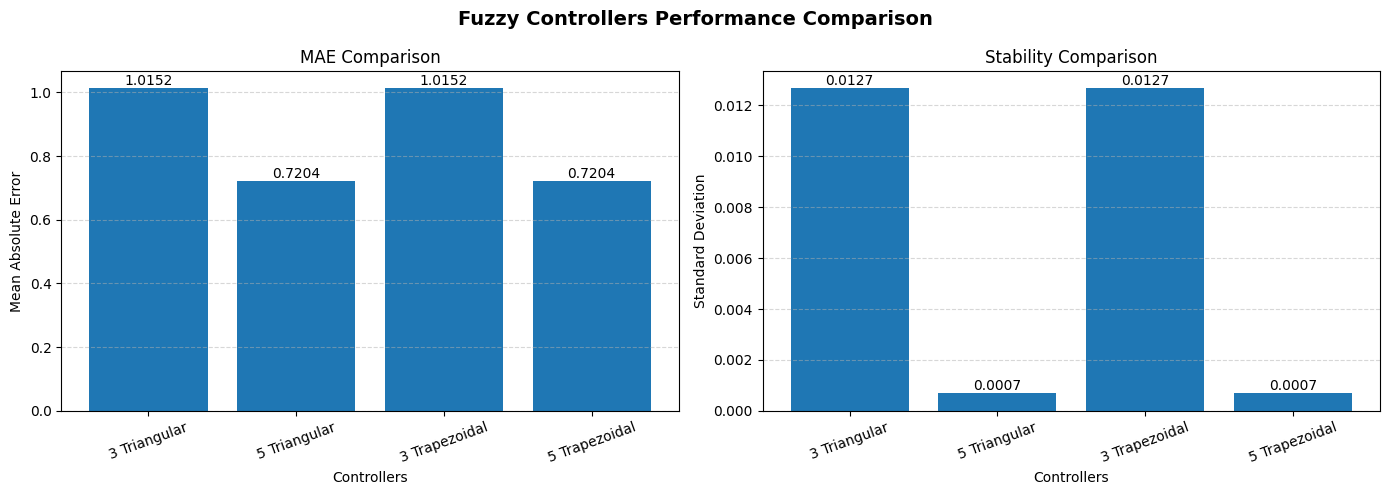

Comparison chart generated successfully!


In [ ]:
!pip install scikit-fuzzy

import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
import skfuzzy.control as ctrl



# Define Input
error = ctrl.Antecedent(
    np.arange(-10, 11, 1), 'error'
)

# Define Output
heater = ctrl.Consequent(
    np.arange(0, 101, 1), 'heater'
)

print("Input and Output defined successfully!")



# Input Membership Functions

error['Negative'] = fuzz.trimf(
    error.universe, [-10, -10, 0]
)

error['Zero'] = fuzz.trimf(
    error.universe, [-5, 0, 5]
)

error['Positive'] = fuzz.trimf(
    error.universe, [0, 10, 10]
)


# Output Membership Functions

heater['Low'] = fuzz.trimf(
    heater.universe, [0, 0, 50]
)

heater['Medium'] = fuzz.trimf(
    heater.universe, [0, 50, 100]
)

heater['High'] = fuzz.trimf(
    heater.universe, [50, 100, 100]
)

print("Membership Functions created successfully!")



# Plot Input Membership Functions

error.view()
plt.title("Temperature Error Membership Functions")
plt.show()


# Plot Output Membership Functions

heater.view()
plt.title("Heater Power Membership Functions")
plt.show()



# Define Fuzzy Rules

rule1 = ctrl.Rule(
    error['Negative'], heater['Low']
)

rule2 = ctrl.Rule(
    error['Zero'], heater['Medium']
)

rule3 = ctrl.Rule(
    error['Positive'], heater['High']
)

# Create Fuzzy Control System

system = ctrl.ControlSystem([
    rule1, rule2, rule3
])

print("Fuzzy Rules created successfully!")



simulation = ctrl.ControlSystemSimulation(system)

target_temp = 23
current_temp = 17

temperature_error = target_temp - current_temp

simulation.input['error'] = temperature_error

simulation.compute()

heater_power = simulation.output['heater']

print("Target Temperature:", target_temp)
print("Current Temperature:", current_temp)
print("Temperature Error:", temperature_error)
print("Heater Power:", round(heater_power, 2), "%")


target_temp = 23
room_temp = 16

temperatures = []
powers = []

for minute in range(120):

    error_value = target_temp - room_temp

    sim = ctrl.ControlSystemSimulation(system)

    sim.input['error'] = np.clip(error_value, -10, 10)

    sim.compute()

    power = sim.output['heater']

    # Room temperature model
    room_temp += (
        0.5 * power / 100
        - 0.05 * (room_temp - 18)
    )

    temperatures.append(room_temp)
    powers.append(power)

print("Simulation completed!")
print("Final Temperature:", round(room_temp, 2))



plt.figure(figsize=(10, 5))

plt.plot(
    temperatures,
    label="Room Temperature"
)

plt.axhline(
    y=target_temp,
    linestyle='--',
    label="Target Temperature"
)

plt.xlabel("Time (Minutes)")
plt.ylabel("Temperature (Celsius)")

plt.title("Fuzzy Temperature Controller Simulation")

plt.legend()
plt.grid()
plt.show()




def create_controller(n, shape):

    e = ctrl.Antecedent(
        np.arange(-10, 11, 1), 'error'
    )

    h = ctrl.Consequent(
        np.arange(0, 101, 1), 'heater'
    )

    input_points = np.linspace(-10, 10, n)
    output_points = np.linspace(0, 100, n)

    # Create Membership Functions
    for i in range(n):

        if shape == 'triangular':

            if i == 0:
                ep = [input_points[0], input_points[0], input_points[1]]
                hp = [output_points[0], output_points[0], output_points[1]]

            elif i == n - 1:
                ep = [input_points[-2], input_points[-1], input_points[-1]]
                hp = [output_points[-2], output_points[-1], output_points[-1]]

            else:
                ep = [input_points[i-1], input_points[i], input_points[i+1]]
                hp = [output_points[i-1], output_points[i], output_points[i+1]]

            e[f's{i}'] = fuzz.trimf(e.universe, ep)
            h[f's{i}'] = fuzz.trimf(h.universe, hp)

        elif shape == 'trapezoidal':

            if i == 0:
                ep = [input_points[0], input_points[0],
                      input_points[0], input_points[1]]
                hp = [output_points[0], output_points[0],
                      output_points[0], output_points[1]]

            elif i == n - 1:
                ep = [input_points[-2], input_points[-1],
                      input_points[-1], input_points[-1]]
                hp = [output_points[-2], output_points[-1],
                      output_points[-1], output_points[-1]]

            else:
                ep = [input_points[i-1], input_points[i],
                      input_points[i], input_points[i+1]]
                hp = [output_points[i-1], output_points[i],
                      output_points[i], output_points[i+1]]

            e[f's{i}'] = fuzz.trapmf(e.universe, ep)
            h[f's{i}'] = fuzz.trapmf(h.universe, hp)

    # Create Fuzzy Rules
    rules = []

    for i in range(n):
        rules.append(
            ctrl.Rule(e[f's{i}'], h[f's{i}'])
        )

    return ctrl.ControlSystem(rules)


print("Controller function created successfully!")


def run_experiment(n, shape):

    system = create_controller(n, shape)

    target = 23
    temp = 16

    temperatures = []
    powers = []

    for minute in range(120):

        error_value = np.clip(target - temp, -10, 10)

        sim = ctrl.ControlSystemSimulation(system)

        sim.input['error'] = error_value
        sim.compute()

        power = sim.output['heater']

        # Room temperature model
        temp += (
            0.5 * power / 100
            - 0.05 * (temp - 18)
        )

        temperatures.append(temp)
        powers.append(power)

    return temperatures, powers


experiments = {}

for n in [3, 5]:
    for shape in ['triangular', 'trapezoidal']:

        name = f'{n} MFs - {shape}'

        temperatures, powers = run_experiment(n, shape)

        experiments[name] = {
            'temperatures': temperatures,
            'powers': powers
        }

        print(name, "completed!")

print("All experiments completed successfully!")



plt.figure(figsize=(12, 6))

for name, result in experiments.items():

    plt.plot(
        result['temperatures'],
        label=name
    )

plt.axhline(
    y=23,
    color='black',
    linestyle='--',
    label='Target Temperature'
)

plt.xlabel("Time (Minutes)")
plt.ylabel("Temperature (Celsius)")

plt.title("Comparison of Fuzzy Controllers")

plt.legend()
plt.grid()
plt.show()



print("FINAL RESULTS")
print("=" * 60)

for name, result in experiments.items():

    temps = np.array(result['temperatures'])

    mae = np.mean(np.abs(23 - temps))

    stability = np.std(temps[-30:])

    overshoot = max(0, np.max(temps) - 23)

    print("\n", name)
    print("MAE:", round(mae, 4))
    print("Stability:", round(stability, 4))
    print("Overshoot:", round(overshoot, 4))

    print("-" * 40)



import matplotlib.pyplot as plt
import numpy as np

controllers = [
    '3 Triangular',
    '5 Triangular',
    '3 Trapezoidal',
    '5 Trapezoidal'
]

mae = [1.0152, 0.7204, 1.0152, 0.7204]
stability = [0.0127, 0.0007, 0.0127, 0.0007]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# MAE Comparison
bars1 = ax1.bar(controllers, mae)

ax1.set_title('MAE Comparison')
ax1.set_ylabel('Mean Absolute Error')
ax1.set_xlabel('Controllers')
ax1.grid(axis='y', linestyle='--', alpha=0.5)
ax1.tick_params(axis='x', rotation=20)

for bar in bars1:
    value = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width()/2,
        value,
        f'{value:.4f}',
        ha='center',
        va='bottom'
    )

# Stability Comparison
bars2 = ax2.bar(controllers, stability)

ax2.set_title('Stability Comparison')
ax2.set_ylabel('Standard Deviation')
ax2.set_xlabel('Controllers')
ax2.grid(axis='y', linestyle='--', alpha=0.5)
ax2.tick_params(axis='x', rotation=20)

for bar in bars2:
    value = bar.get_height()
    ax2.text(
        bar.get_x() + bar.get_width()/2,
        value,
        f'{value:.4f}',
        ha='center',
        va='bottom'
    )

plt.suptitle('Fuzzy Controllers Performance Comparison',
             fontsize=14, fontweight='bold')

plt.tight_layout()

plt.savefig('MAE_Stability_Comparison.png',
            dpi=300, bbox_inches='tight')

plt.show()

print("Comparison chart generated successfully!")





